# Koopman–von Neumann: energy conservation

Same oscillator as [`sho_kinetic_energy`](sho_kinetic_energy.ipynb), on three axes instead of one,
and a different question:

- **There:** one trajectory, numeric, checked against a known curve.
- **Here:** symbolic. $T(t)+V(t)$ has no $t$ in it.
- So energy is conserved for *every* initial condition.

:::{seealso}
- [Vocabulary and symbols](../../docs/concepts.md) defines observable, expectation value, bra, ket,
  vacuum and the three generators $\mathcal K$, $\mathcal L$ and $\mathcal L_{\rm KvN}$.
- [`sho_kinetic_energy`](sho_kinetic_energy.ipynb) runs the same oscillator on one axis,
  numerically.
:::

| this notebook's notation | is |
|---|---|
| $\{X,Y\}_+$ | the anticommutator $XY+YX$ |
| `U[s]`, `K[s]` | in printed operator expressions: multiply by $u_s$, and $\partial_s$ |
| $q_i$, $p_i$ | position and momentum along axis $i$ |
| $m$, $\omega$ | mass and angular frequency |
| $T$, $V$ | kinetic and potential energy |
| $G$ | whichever observable matrix is being evolved |
| $\boldsymbol c_0$ | the initial state, as coefficients on the basis |


## 1. The 3D harmonic oscillator

A harmonic oscillator's equations of motion are second order, so the state carries both position and
momentum: $u=(q_x,q_y,q_z,p_x,p_y,p_z)$, six sites.

Sites $0..2$ are positions, $3..5$ momenta, and the right-hand side is linear in all of them.

$$\frac{dq_i}{dt}=\frac{p_i}{m},\qquad\frac{dp_i}{dt}=-m\omega^{2}q_i,$$

encoded here as one piecewise right-hand side over a single site index.

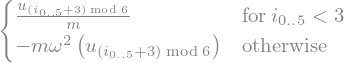

In [1]:
import sympy as sp
from lin_ode import OrdinaryDifferentialSystem
sp.init_printing()

m, omega = sp.symbols('m omega', positive=True)
u = sp.IndexedBase('u')
i = sp.Idx('i', (0, 5))    # 0,1,2 = q_x,q_y,q_z ; 3,4,5 = p_x,p_y,p_z

# dq_i/dt = p_i/m           (i < 3, so u[i+3] is that dof's momentum)
# dp_i/dt = -m*omega**2*q_i (i >= 3, so u[i-3] is that dof's position)
rhs = sp.Piecewise(
    (u[i + 3] / m, i < 3),
    (-m * omega**2 * u[i - 3], True),
)
ode = OrdinaryDifferentialSystem.from_sympy(rhs, u, (i,))
ode.equation.expr

## 2. Observables as `ObservableExpression`

`ObservableExpression` holds a function of the raw state `u`, written like an ODE right-hand side.
Here that function is the potential energy over the three position sites:

$$V(u)=\tfrac{1}{2}m\omega^{2}\bigl(u_0^{2}+u_1^{2}+u_2^{2}\bigr)$$

`get_matrix` projects the observable onto a basis and returns its matrix $M_V$.

Indexing that with a list of basis-state labels materialises the block on those states.

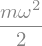

In [2]:
from lin_ode import ObservableExpression
from lin_ode.basis import CarlemanBasis

k = sp.Idx('k', (0, 2))                       # position sites
V_ie = ObservableExpression.from_sympy(
    m * omega**2 * sp.Sum(u[k]**2, (k, 0, 2)).doit() / 2, u, (k,)
)

basis = CarlemanBasis(6, degree=2)
V_matrix = V_ie.get_matrix(basis)
V_matrix[((0, 2),), ()]   # <q_x**2| V |vac>

## 3. $\mathcal L_{\rm KvN}$, the KvN operator

KvN symmetrizes the Koopman generator:

$$\mathcal L_{\rm KvN}=-\tfrac12\sum_s\bigl(\partial_s f_s+f_s\partial_s\bigr)
=-\mathcal K-\tfrac12\nabla\!\cdot\!f$$

$\partial_s$ is anti-Hermitian and $f_s$ is Hermitian, so the anticommutator is anti-Hermitian. That
is why the norm of a state stays constant under application of $e^{\mathcal L_{\rm KvN}t}$.

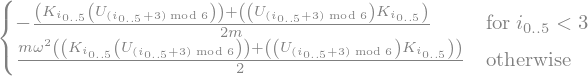

In [3]:
import sympy as sp
from lin_ode.operators import KoopmanVonNeumann

method = KoopmanVonNeumann()
operator = method.create_operator(ode)
# the lifted operator word per Piecewise arm: -(f*K + K*f)/2 in the U/K algebra
sp.Piecewise(*operator.cases).simplify()

### The invariant block on one axis

`labels` names six basis states: the $x$ phase space, sites $0=q_x$ and $3=p_x$, up to degree 2.

No basis state outside the block enters:

- same $\omega$ on all three axes, no cross terms
- so $x$, $y$ and $z$ never mix
- $\mathcal L_{\rm KvN}$ conserves total degree exactly

These six states are an exact invariant block.

### Why the $L^2$ requirement does not apply here

The initial state $\psi_0=\delta(u_0-q_x(0))\,\delta(u_3-p_x(0))$ is a point, not a density. No
integral $\int\rho\,du$ appears in this notebook.

`OperatorMatrix` applies the general rule anyway, so it raises `IncompatibleBasisError` on
`CarlemanBasis`. The entries below therefore come from `build_matrix`, one layer below, which takes
flat indices and does not check the basis.

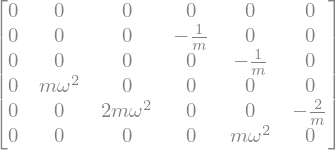

In [4]:
from lin_ode.matrix import build_matrix

labels = [(), ((3, 1),), ((3, 2),), ((0, 1),), ((0, 1), (3, 1)), ((0, 2),)]

flat = basis.flat_indices_of_structured_indices
M_kvn = build_matrix(operator, flat(labels), flat(labels), basis)
M_kvn

In [5]:
# the section-3 claim, checked: anti-Hermitian means a purely imaginary spectrum
print({sp.simplify(v): m for v, m in M_kvn.eigenvals().items()})

{0: 2, -I*omega: 1, I*omega: 1, -2*I*omega: 1, 2*I*omega: 1}


## 4. Observables for kinetic and potential energy

Kinetic energy,

$$T(u)=\frac{u_3^{2}+u_4^{2}+u_5^{2}}{2m},$$

sums over the three momentum sites, as $V$ does over the position sites.

Both act only on the vacuum column. A degree-2 observable ($T$ or $V$) against a ket
$\lvert\alpha\rangle$ goes above the degree whenever

$$\deg T+\deg\lvert\alpha\rangle>2,$$

so every column but the vacuum's is zero.

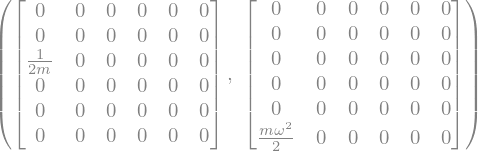

In [6]:
j = sp.Idx('j', (3, 5))                       # momentum sites
T_ie = ObservableExpression.from_sympy(
    sp.Sum(u[j]**2, (j, 3, 5)).doit() / (2 * m), u, (j,)
)
T_matrix = T_ie.get_matrix(basis)

T = T_matrix[labels, labels]
V = V_matrix[labels, labels]
T, V

## 5. Conjugation by $e^{M_{\mathcal L_{\rm KvN}}t}$

An observable evolves by conjugation, as in the Heisenberg picture:

$$G(t)=e^{-M_{\mathcal L_{\rm KvN}}t}\;G\;e^{M_{\mathcal L_{\rm KvN}}t}$$

The spectrum printed above is imaginary, so the conjugation is a rotation and the norm stays
constant.


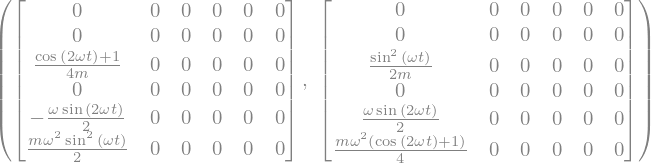

In [7]:
t = sp.symbols('t', real=True)
exp_minus = (-M_kvn * t).exp()
exp_plus = (M_kvn * t).exp()
T_t = sp.simplify(exp_minus * T * exp_plus)
V_t = sp.simplify(exp_minus * V * exp_plus)
T_t, V_t

### Energy conservation

$T$ and $V$ each oscillate at $2\omega$, in antiphase, and their sum is constant.

In [8]:
assert sp.simplify(T_t + V_t - (T + V)) == sp.zeros(*T.shape)
print("T(t) + V(t) == T(0) + V(0) -- total energy is conserved exactly.")

T(t) + V(t) == T(0) + V(0) -- total energy is conserved exactly.


## 6. Time series for a chosen trajectory

Pin the initial condition to one classical point:

$$\psi_0(u)=\delta\bigl(u_0-q_x(0)\bigr)\,\delta\bigl(u_3-p_x(0)\bigr)$$

### Sifting to coefficients

By the sifting property, $\psi_0$'s coefficient on each basis function is that function evaluated at
$\bigl(q_x(0),p_x(0)\bigr)$.

So `c0` rewrites each basis state as its monomial, then substitutes the pinned point.


### The expectation value

$$\langle G\rangle(t)=\boldsymbol c_0^{\mathsf T}\,G(t)\,\boldsymbol c_0$$


### No normalizer

$\boldsymbol c_0^{\mathsf T}\boldsymbol c_0=3$, yet $\langle E\rangle=\tfrac12$, not $\tfrac16$.

Sifting already evaluated the polynomial at a point, and a point needs no average.

### Conservation for any initial condition

Kept symbolic in $q_x(0)$, $p_x(0)$, $m$ and $\omega$, the sum $T(t)+V(t)$ carries no $t$ at all.


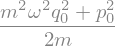

In [9]:
q0, p0 = sp.symbols('q0 p0', real=True)   # q_x(0), p_x(0)

psi_0 = sp.DiracDelta(u[0] - q0) * sp.DiracDelta(u[3] - p0)   # KvN wavefunction: a point in phase space

def as_monomial(*factors):   # CarlemanState((site, power), ...) -> u[site]**power * ...
    return sp.Mul(*[u[site] ** power for site, power in factors])

# psi_0's sifting property: its coefficient at each basis label is that basis
# function evaluated at the pinned point (q0, p0)
sift_point = {u[0]: q0, u[3]: p0}
c0 = sp.Matrix([
    basis[label].replace(basis.state_type, as_monomial).subs(sift_point)
    for label in labels
])

V_of_t = sp.simplify((c0.T * V_t * c0)[0])
T_of_t = sp.simplify((c0.T * T_t * c0)[0])
E_of_t = sp.simplify(T_of_t + V_of_t)
E_of_t

For a concrete plot, substitute numbers. Released from rest at maximum displacement:
$q_x(0)=1$, $p_x(0)=0$, $m=\omega=1$.

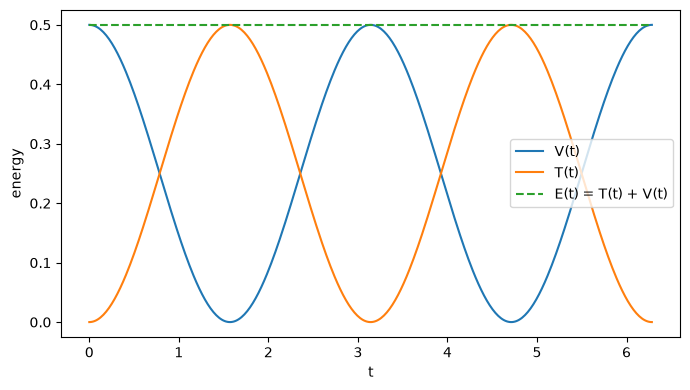

In [10]:
import numpy as np
import matplotlib.pyplot as plt

subs = {m: 1, omega: 1, q0: 1, p0: 0}
V_num = V_of_t.subs(subs)
T_num = T_of_t.subs(subs)
E_num = E_of_t.subs(subs)

t_values = np.linspace(0, 2 * np.pi / subs[omega], 400)
V_values = sp.lambdify(t, V_num, 'numpy')(t_values)
T_values = sp.lambdify(t, T_num, 'numpy')(t_values)
E_values = np.full_like(t_values, float(E_num))   # E(t) is exactly constant

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_values, V_values, label='V(t)')
ax.plot(t_values, T_values, label='T(t)')
ax.plot(t_values, E_values, label='E(t) = T(t) + V(t)', linestyle='--')
ax.set_xlabel('t')
ax.set_ylabel('energy')
ax.legend()
fig.tight_layout()

**$T$ and $V$ swap at $2\omega$; $E$ is flat at $\tfrac12$.**

Each energy rises by the amount the other falls, so their sum is a horizontal line. That is the
conservation proved symbolically above, now at concrete numbers.

---

[← Pivot switching: logistic](psc_logistic_switching.ipynb) · [Notebook index](../README.md)